# Image embeddings → kNN → clustering

Real data: 2,000 photos from **CIFAR-10** (10 classes: planes, cars, birds, cats, deer, dogs, frogs, horses, ships, trucks).

We compare two ways to turn an image into a vector:
- **DINOv2** learns visual patterns from images. It is useful for image similarity and clustering.
- **CLIP** learns to match images with language. It supports image similarity *and* text-to-image search.

Then we use both embedding sets with **UMAP**, **kNN**, and clustering. Runs on CPU (embedding may take several minutes); a GPU helps.

In [ ]:
!pip install -q transformers sentence-transformers umap-learn torchvision scikit-learn matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\dbhagria\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## 1. Load a real dataset
We take 200 random images per class so everything runs fast.

Files already downloaded and verified
10000


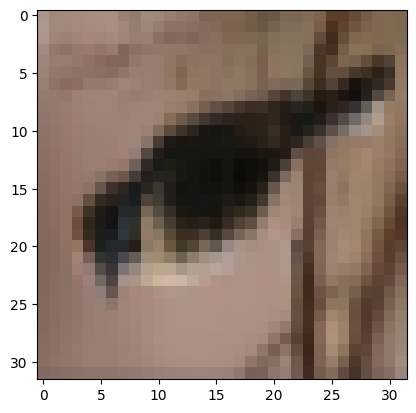

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
import torchvision
df = CIFAR10(root="data", train= False, download=True, transform=torchvision.transforms.ToTensor())
classes = df.classes
classes

test_loader = DataLoader(df, batch_size=1, shuffle=True)

print(len(test_loader))

for i, l in test_loader:
    plt.imshow(i[0].permute(2, 1, 0 ))
    break

Files already downloaded and verified
2000 images


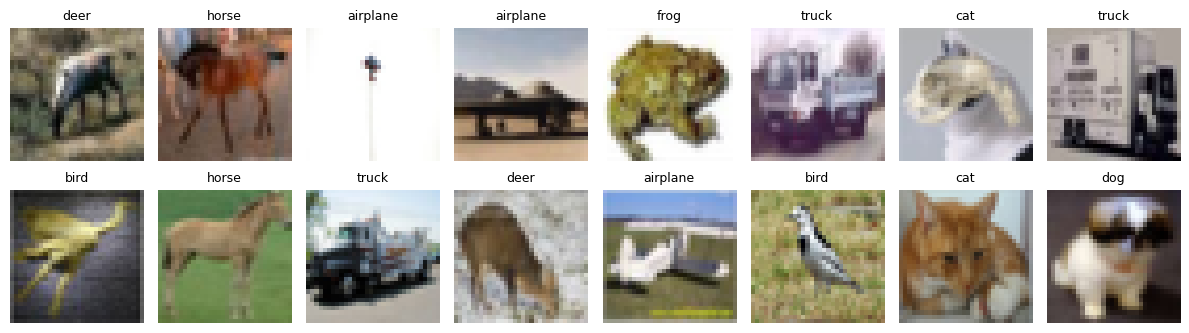

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10

ds = CIFAR10(root="data", train=False, download=True)   # ~170 MB download, first run only
classes = ds.classes
labels_all = np.array(ds.targets)

rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(labels_all == c)[0], 200, replace=False) for c in range(10)])
images = [ds[i][0] for i in idx]   # list of PIL images
y = labels_all[idx]                # true labels (only used for checking, never for clustering)
print(len(images), "images")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, rng.choice(len(images), 16, replace=False)):
    ax.imshow(images[i]); ax.set_title(classes[y[i]], fontsize=9); ax.axis("off")
plt.tight_layout()
plt.show()


## 2. Images → embeddings: DINOv2 and CLIP
An **embedding** is a list of numbers that represents an image. Images with similar content should have vectors close together.

- **DINOv2:** Think of it as a visual-pattern learner. It was trained to make useful image representations without needing text descriptions. Here we use its CLS token, giving a 768-number vector.
- **CLIP:** Think of it as two translators, one for images and one for text. During training, it learned to put a matching image and caption near each other in one shared space. That is why we can search images with a sentence. Here its image vectors have 512 numbers.

We normalize each vector to length 1, which makes the dot product equal cosine similarity.

In [26]:
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModel
from sentence_transformers import SentenceTransformer

# DINOv2 image embeddings (768 dimensions)
device = "cuda" if torch.cuda.is_available() else "cpu"
dino_processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino_model = AutoModel.from_pretrained("facebook/dinov2-base").to(device).eval()

batch_size = 64
dino_batches = []
with torch.inference_mode():
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        inputs = dino_processor(images=batch, return_tensors="pt").to(device)
        # The CLS token summarizes the image for DINOv2.
        features = dino_model(**inputs).last_hidden_state[:, 0]
        dino_batches.append(F.normalize(features, p=2, dim=1).cpu())
emb_dino = torch.cat(dino_batches).numpy()

# CLIP image embeddings (512 dimensions); image and text vectors share this space.
clip_model = SentenceTransformer("clip-ViT-B-32", device=device)
emb_clip = clip_model.encode(
    images, batch_size=batch_size, normalize_embeddings=True,
    show_progress_bar=True, convert_to_numpy=True
)

# Keep the remaining single-embedding examples focused on DINOv2.
emb = emb_dino
print("DINOv2:", emb_dino.shape, "| CLIP:", emb_clip.shape)

c:\Users\dbhagria\AppData\Local\miniconda3\envs\dl2\Lib\site-packages\torchvision\datapoints\__init__.py:12: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Please submit any feedback you may have in this issue: https://github.com/pytorch/vision/issues/6753, and you can also check out https://github.com/pytorch/vision/issues/7319 to learn more about the APIs that we suspect might involve future changes. You can silence this warning by calling torchvision.disable_beta_transforms_warning().
  warnings.warn(_BETA_TRANSFORMS_WARNING)
c:\Users\dbhagria\AppData\Local\miniconda3\envs\dl2\Lib\site-packages\torchvision\transforms\v2\__init__.py:54: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Pl

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

c:\Users\dbhagria\AppData\Local\miniconda3\envs\dl2\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dbhagria\.cache\huggingface\hub\models--facebook--dinov2-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

c:\Users\dbhagria\AppData\Local\miniconda3\envs\dl2\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dbhagria\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

DINOv2: (2000, 768) | CLIP: (2000, 512)


In [43]:
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModel
from sentence_transformers import SentenceTransformer


device = "cuda" if torch.cuda.is_available() else "cpu"

dino_processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
dino_model = AutoModel.from_pretrained("facebook/dinov2-base")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

In [48]:
batch_size = 64
dino_batches = []

with torch.inference_mode():
    for start in range(0, len(images), batch_size):
        batch = images[start:start+ batch_size]
        inputs = dino_processor(images = batch, return_tensors = "pt").to(device)

        features = dino_model(**inputs).last_hidden_state[:, 0]
        dino_batches.append(F.normalize(features, p=2, dim=1).cpu())
    emb_dino = torch.cat(dino_batches).numpy()

In [49]:
clip_model = SentenceTransformer("clip-ViT-B-32", device = device)
emb_clip = clip_model.encode(images, batch_size=64, normalize_embeddings=True, convert_to_numpy=True)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

C:\Users\dbhagria\AppData\Local\Temp\ipykernel_20236\305895935.py:6: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(xy_dino[:, 0], xy_dino[:, 1], cmap='tab10')


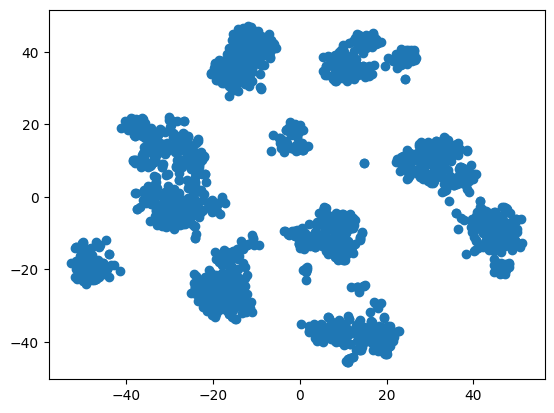

In [55]:
from sklearn.manifold import TSNE

xy_dino = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=0).fit_transform(emb_dino)
xy_clip = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state= 0).fit_transform(emb_clip)

plt.scatter(xy_dino[:, 0], xy_dino[:, 1], cmap='tab10')

C:\Users\dbhagria\AppData\Local\Temp\ipykernel_20236\1101274383.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(xy_clip[:, 0], xy_clip[:, 1], cmap='tab10')


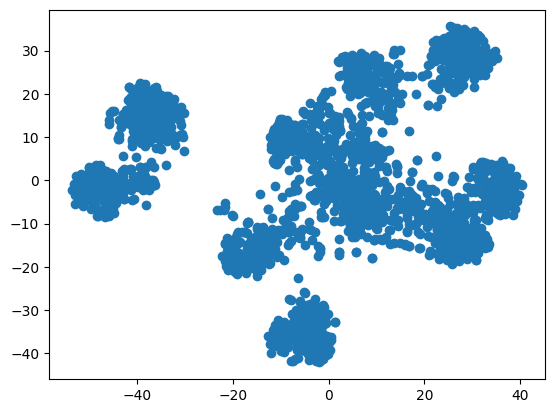

In [56]:
plt.scatter(xy_clip[:, 0], xy_clip[:, 1], cmap='tab10')

## 3. Compare the embedding spaces
UMAP squashes each model's vectors down to 2D while trying to keep neighbors close. Colors are true labels. The two UMAP plots are separate maps, so compare how well each color groups together—not the coordinates between plots.

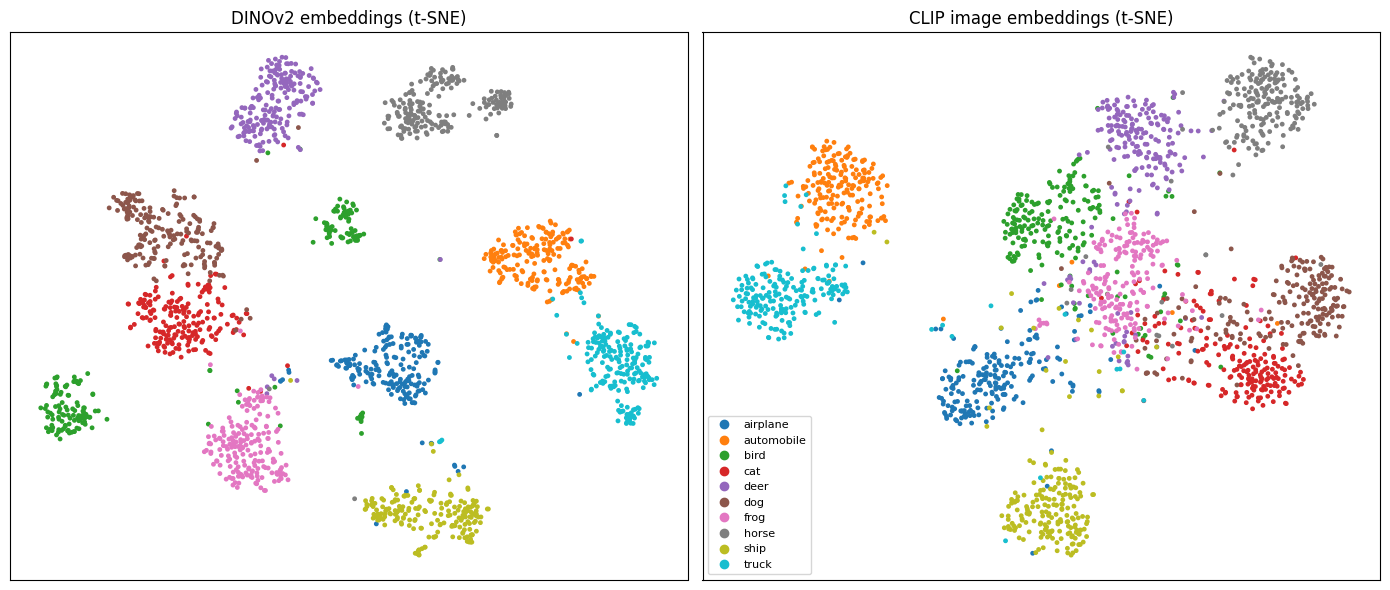

In [57]:
from sklearn.manifold import TSNE

xy_dino = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=0).fit_transform(emb_dino)
xy_clip = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=0).fit_transform(emb_clip)
xy = xy_dino  # Used by the DINOv2 HDBSCAN example below.

def scatter(ax, color_ids, title, cmap="tab10", vmax=9.5, coords=xy):
    ax.scatter(coords[:, 0], coords[:, 1], c=color_ids, cmap=cmap, s=6, vmin=-0.5, vmax=vmax)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scatter(axes[0], y, "DINOv2 embeddings (t-SNE)", coords=xy_dino)
scatter(axes[1], y, "CLIP image embeddings (t-SNE)", coords=xy_clip)
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(c), label=classes[c]) for c in range(10)]
axes[1].legend(handles=handles, fontsize=8, loc="best")
plt.tight_layout(); plt.show()

## 4. kNN
### 4a. Find similar images
Each row starts with a query image, followed by its 5 nearest neighbors from DINOv2 and its 5 nearest neighbors from CLIP. Distance `d` is cosine distance (0 = identical).

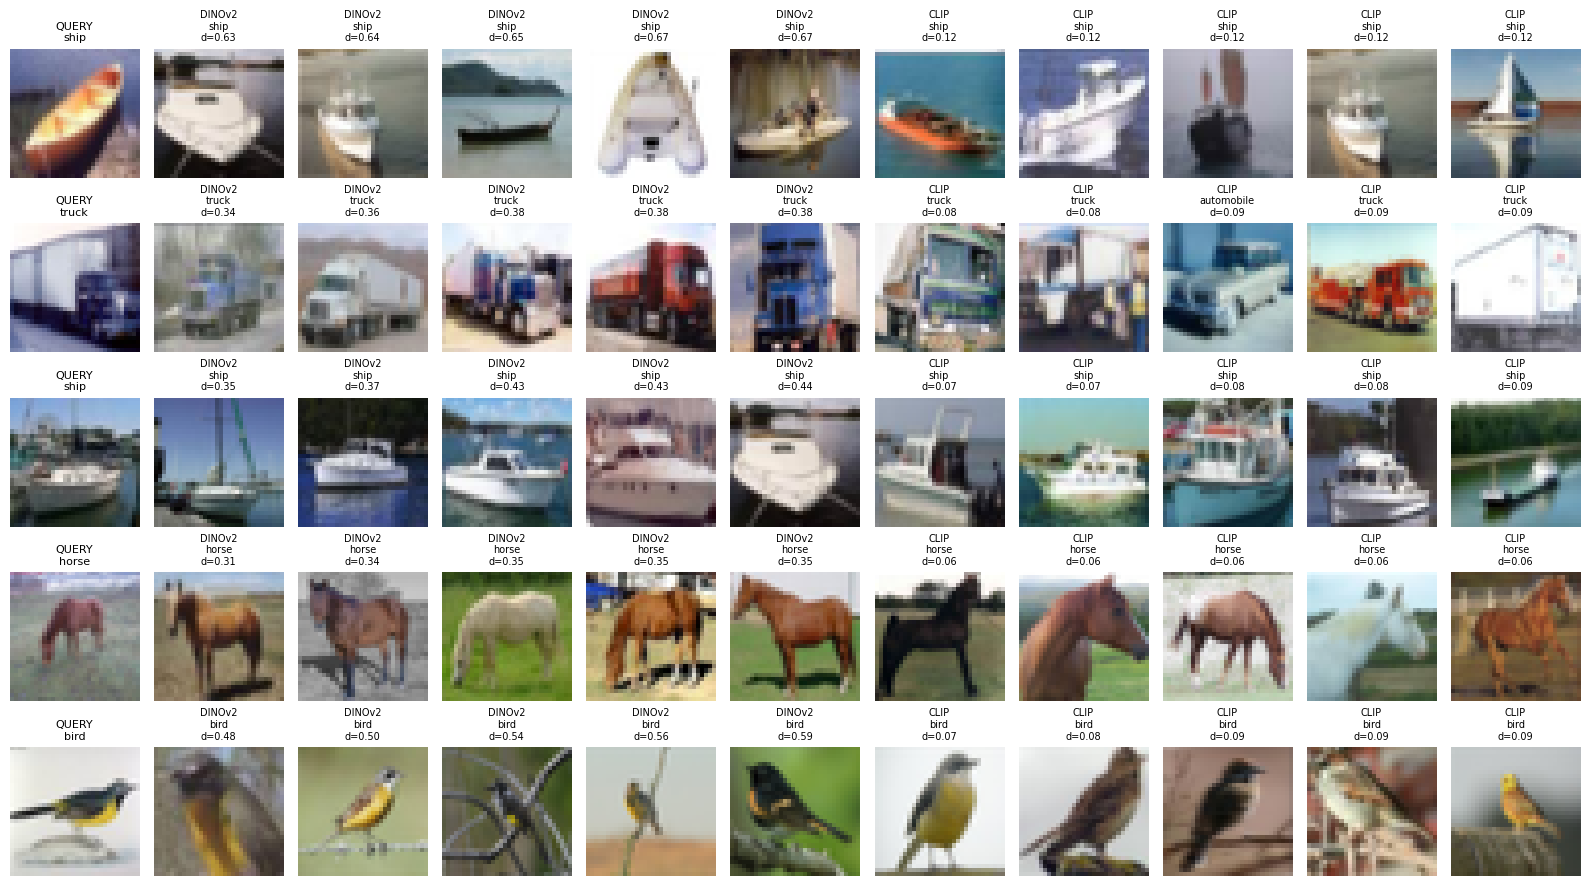

In [ ]:
from sklearn.neighbors import NearestNeighbors

queries = rng.choice(len(images), 5, replace=False)
neighbors = {
    "DINOv2": NearestNeighbors(n_neighbors=6, metric="cosine").fit(emb_dino).kneighbors(emb_dino[queries]),
    "CLIP": NearestNeighbors(n_neighbors=6, metric="cosine").fit(emb_clip).kneighbors(emb_clip[queries]),
}

fig, axes = plt.subplots(len(queries), 11, figsize=(16, 9), squeeze=False)
for row, query_idx in enumerate(queries):
    axes[row, 0].imshow(images[query_idx])
    axes[row, 0].set_title(f"QUERY\n{classes[y[query_idx]]}", fontsize=8)

    for model, (distances, indices), start in zip(neighbors, neighbors.values(), (1, 6)):
        for column, (index, distance) in enumerate(zip(indices[row][1:], distances[row][1:]), start):
            axes[row, column].imshow(images[index])
            axes[row, column].set_title(
                f"{model}\n{classes[y[index]]}\nd={distance:.2f}", fontsize=7
            )

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [63]:
from sklearn.neighbors import NearestNeighbors

neighbour_dino = NearestNeighbors(n_neighbors=6, metric="cosine").fit(emb_dino).kneighbors(emb_dino[queries])

print(neighbour_dino[0])

[[0.0000000e+00 6.2980646e-01 6.4009142e-01 6.4698076e-01 6.6537106e-01
  6.7031717e-01]
 [0.0000000e+00 3.4000415e-01 3.5898542e-01 3.7701213e-01 3.8255298e-01
  3.8418472e-01]
 [0.0000000e+00 3.5430330e-01 3.7359202e-01 4.2956334e-01 4.3195683e-01
  4.3712115e-01]
 [0.0000000e+00 3.1101245e-01 3.4373903e-01 3.4625661e-01 3.4761286e-01
  3.5091305e-01]
 [1.1920929e-07 4.7631091e-01 5.0497144e-01 5.3617543e-01 5.5977768e-01
  5.9353805e-01]]


### 4b. Compare kNN as a classifier
Hide the labels of 30% of the images, then label each one by majority vote of its 10 nearest labeled neighbors. Both models use the same train/test split; random guessing would get 10%.

DINOv2 kNN accuracy: 96.7%
CLIP kNN accuracy:   89.7%


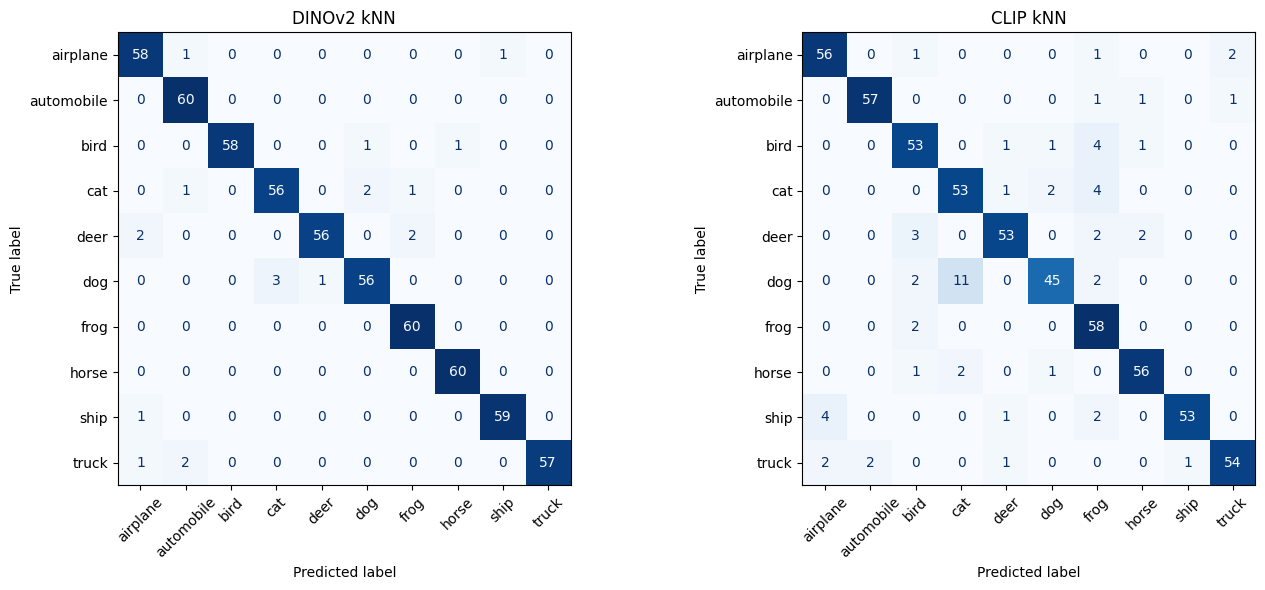

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay

train_idx, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.3, stratify=y, random_state=0
)
ytr, yte = y[train_idx], y[test_idx]

knn_dino = KNeighborsClassifier(n_neighbors=10, metric="cosine").fit(emb_dino[train_idx], ytr)
knn_clip = KNeighborsClassifier(n_neighbors=10, metric="cosine").fit(emb_clip[train_idx], ytr)
print(f"DINOv2 kNN accuracy: {knn_dino.score(emb_dino[test_idx], yte):.1%}")
print(f"CLIP kNN accuracy:   {knn_clip.score(emb_clip[test_idx], yte):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ConfusionMatrixDisplay.from_estimator(
    knn_dino, emb_dino[test_idx], yte, display_labels=classes,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("DINOv2 kNN")
ConfusionMatrixDisplay.from_estimator(
    knn_clip, emb_clip[test_idx], yte, display_labels=classes,
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[1]
)
axes[1].set_title("CLIP kNN")
plt.tight_layout(); plt.show()

### 4c. Bonus: compare image search with DINOv2 and CLIP
Use the same image as a query in each model's image-embedding space. CLIP has an extra capability too: because its text and image encoders share a space, it can search images from a sentence.

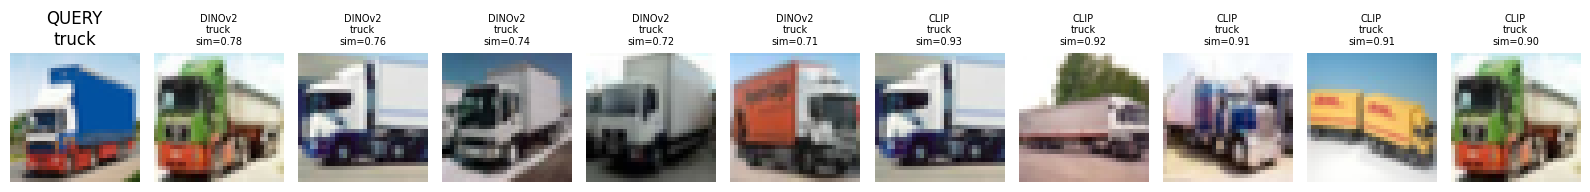

In [66]:
query_idx = int(rng.integers(len(images)))
sim_dino = emb_dino @ emb_dino[query_idx]
sim_clip = emb_clip @ emb_clip[query_idx]
sim_dino[query_idx] = sim_clip[query_idx] = -np.inf  # Exclude the query itself
top_dino = np.argsort(-sim_dino)[:5]
top_clip = np.argsort(-sim_clip)[:5]

fig, axes = plt.subplots(1, 11, figsize=(16, 2.3))
axes[0].imshow(images[query_idx])
axes[0].set_title(f"QUERY\n{classes[y[query_idx]]}")
axes[0].axis("off")
for ax, j in zip(axes[1:6], top_dino):
    ax.imshow(images[j]); ax.axis("off")
    ax.set_title(f"DINOv2\n{classes[y[j]]}\nsim={sim_dino[j]:.2f}", fontsize=7)
for ax, j in zip(axes[6:], top_clip):
    ax.imshow(images[j]); ax.axis("off")
    ax.set_title(f"CLIP\n{classes[y[j]]}\nsim={sim_clip[j]:.2f}", fontsize=7)
plt.tight_layout(); plt.show()

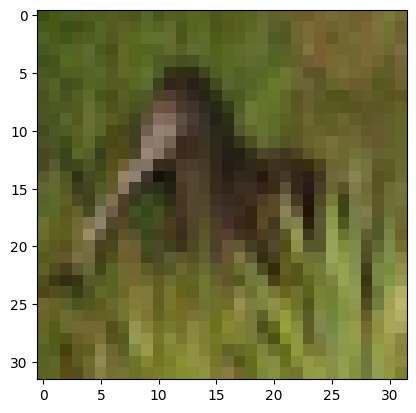

In [78]:
text = "grass"
encoding = clip_model.encode(text, normalize_embeddings=True, convert_to_numpy=True)
similarities = emb_clip @ encoding
top_5 = np.argsort(similarities)[-6:]
for i in top_5:
    plt.imshow(images[i])
    

#### CLIP-only: search images with text
CLIP learned to place matching captions and images near each other. Encode a sentence with CLIP's text encoder, then rank images by cosine similarity. DINOv2 has no text encoder, so this feature is specific to CLIP.

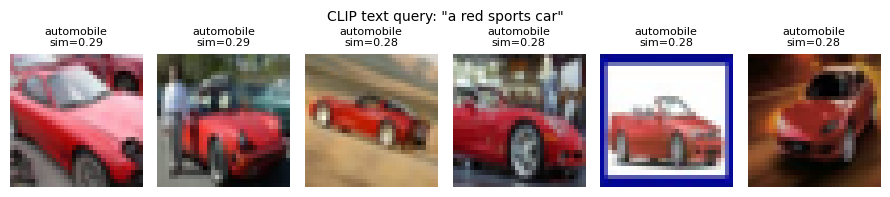

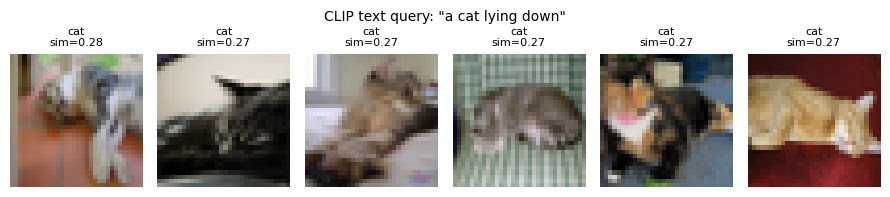

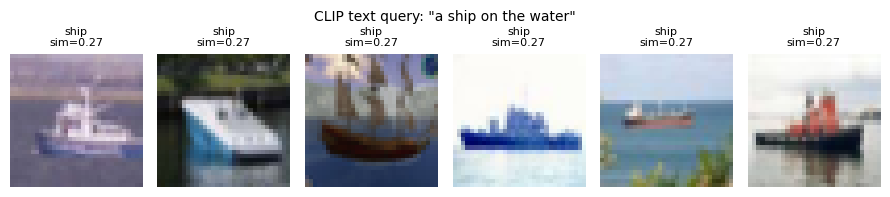

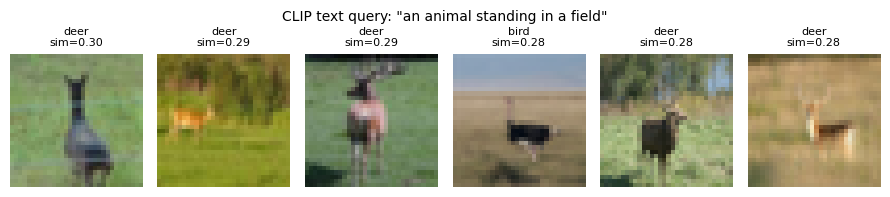

In [67]:
for text in ["a red sports car", "a cat lying down", "a ship on the water", "an animal standing in a field"]:
    text_embedding = clip_model.encode([text], normalize_embeddings=True, convert_to_numpy=True)
    similarities = emb_clip @ text_embedding[0]
    top = np.argsort(-similarities)[:6]

    fig, axes = plt.subplots(1, 6, figsize=(9, 2))
    fig.suptitle(f'CLIP text query: "{text}"', fontsize=10)
    for ax, j in zip(axes, top):
        ax.imshow(images[j])
        ax.set_title(f"{classes[y[j]]}\nsim={similarities[j]:.2f}", fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 5. Clustering (no labels used)
### 5a. Compare K-means with k = 10
We ask each model to find 10 groups without seeing labels. Cluster IDs are arbitrary, so compare the shapes of the groups, not their colors. ARI scores the match to the true labels: 1.0 = perfect, 0 = random.

DINOv2 ARI: 0.809
CLIP ARI:   0.615


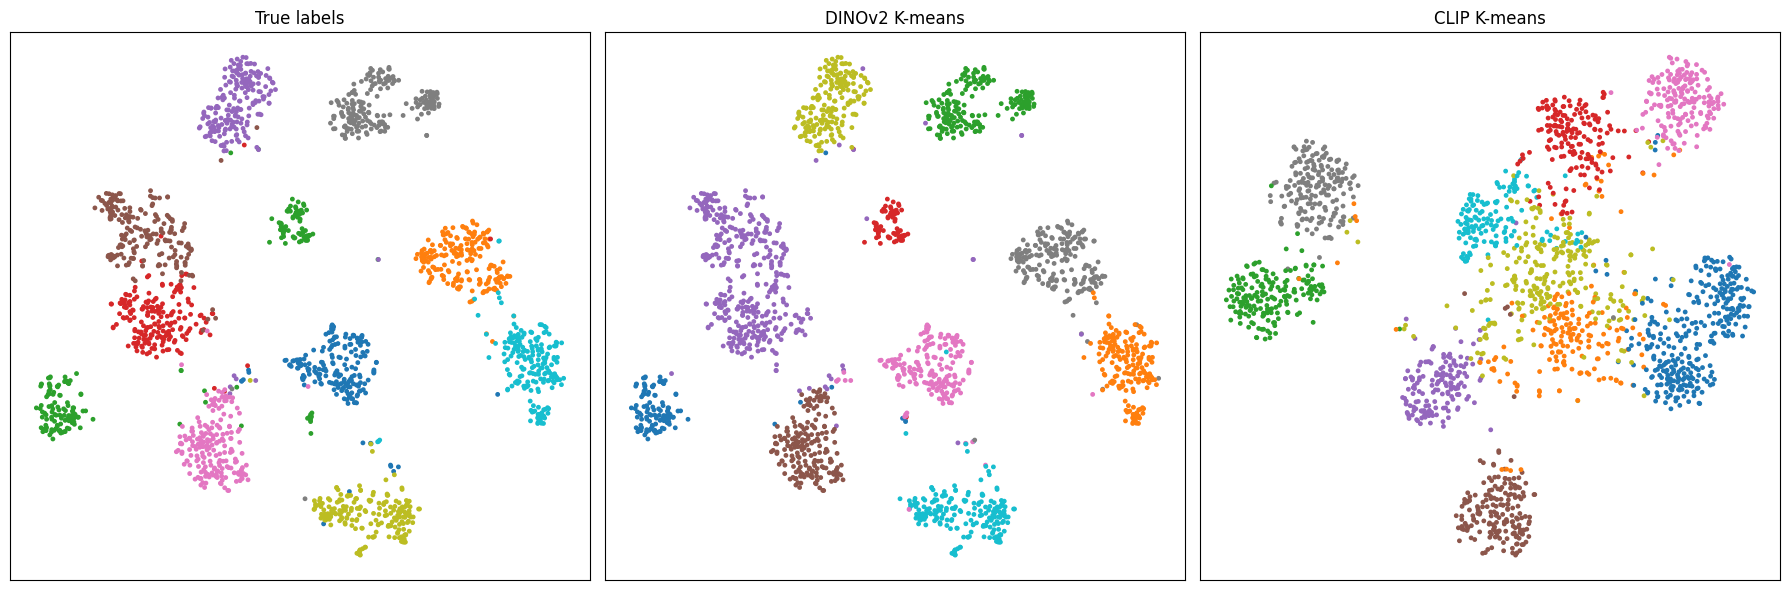

In [65]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

clusters_dino = KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(emb_dino)
clusters_clip = KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(emb_clip)
clusters = clusters_dino  # The cluster-inspection and HDBSCAN sections below use DINOv2.
print("DINOv2 ARI:", round(adjusted_rand_score(y, clusters_dino), 3))
print("CLIP ARI:  ", round(adjusted_rand_score(y, clusters_clip), 3))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
scatter(axes[0], y, "True labels", coords=xy_dino)
scatter(axes[1], clusters_dino, "DINOv2 K-means", coords=xy_dino)
scatter(axes[2], clusters_clip, "CLIP K-means", coords=xy_clip)
plt.tight_layout(); plt.show()

### 5b. What's inside each DINOv2 cluster?
Each row is one DINOv2 cluster: 8 random members, plus which true class dominates it and how pure it is.

In [ ]:
fig, axes = plt.subplots(10, 8, figsize=(8, 12))
for k in range(10):
    members = np.where(clusters == k)[0]
    counts = np.bincount(y[members], minlength=10)
    axes[k, 0].set_title(f"cluster {k}: {counts.max() / len(members):.0%} {classes[counts.argmax()]}  (n={len(members)})",
                         loc="left", fontsize=8)
    for c, ax in enumerate(axes[k]):
        ax.axis("off")
        if c < len(members):
            ax.imshow(images[rng.choice(members)])
plt.tight_layout(); plt.show()

### 5c. HDBSCAN: let the algorithm decide how many clusters
This optional example uses the DINOv2 vectors. Clustering in 768-D can be difficult, so we first reduce them to 10-D with UMAP. HDBSCAN marks points that don't fit anywhere as noise (gray).

In [ ]:
from sklearn.cluster import HDBSCAN

emb10 = umap.UMAP(n_components=10, n_neighbors=15, metric="cosine", random_state=0).fit_transform(emb)
hl = HDBSCAN(min_cluster_size=30).fit_predict(emb10)
print("clusters found:", hl.max() + 1, "| noise points:", (hl == -1).sum())

fig, ax = plt.subplots(figsize=(8, 7))
noise = hl == -1
ax.scatter(xy[noise, 0], xy[noise, 1], c="lightgray", s=5, label="noise")
ax.scatter(xy[~noise, 0], xy[~noise, 1], c=hl[~noise], cmap="tab20", s=6)
ax.set_title(f"HDBSCAN found {hl.max() + 1} clusters on its own"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(); plt.show()

## Try next
- Swap CIFAR-10 for your own folder: `images = [Image.open(p).convert("RGB") for p in glob.glob("my_photos/*.jpg")]`
- Try a larger checkpoint: `facebook/dinov2-large` or `clip-ViT-L-14` (larger and slower)
- Change `n_clusters` or `min_cluster_size` and watch the groups split and merge